# 04. 프로세스 마이닝 — 가입 후 90일, 어떤 순서로 처음 해보는가

**요약**
- **입구가 대회 참가에서 가벼운 활동으로 옮겨갔다.** 활동한 유저의 첫 활동이 대회 참가인 비율 62.3% → 41.4%, 가벼운 활동(투표·팔로우·반응) 30.3% → 46.4%.
- **가벼운 활동은 막다른 길이 됐다.** 가벼운 활동으로 시작한 유저가 90일 안에 참여·창작으로 넘어가는 비율 19.1% → 9.3% (비율 0.49, 95% CI 0.48 ~ 0.50).
- **이미 참여한 뒤의 단계는 그대로다.** 대회 참가 다음 제출 14.1% → 14.0%, 노트북 작성 다음 공개 78.9% → 81.8%. `03`의 "참여 이후 병목 없음"과 일치한다.
- 그래서 병목 후보는 `03`에서 다루지 않은 **가벼운 활동 → 참여** 연결이다. 같은 날 순서 규칙을 뒤집어도 결론은 같다.

입력: `data/processed/event_log.parquet` (`scripts/04_event_log.py`)

In [1]:
import sys, os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from statsmodels.stats.proportion import confint_proportions_2indep

sys.path.append("../src")
sys.path.append(os.path.expanduser("~/.claude/skills/chart-style"))
from metakaggle.config import processed
import viz_style as vs

vs.setup()
FIG = "../docs/figures"
raw = pd.read_parquet(processed("event_log"))
N = {"Golden": 2_041_992, "Stagnation": 5_943_573}
KO = {"Golden": "황금기", "Stagnation": "침체기"}; PERIODS = list(N)
raw.activity.value_counts()

대회 참가     394633
가벼운 활동    298378
노트북 작성     62381
대회 제출      61061
노트북 공개     55324
포럼 글       37075
데이터셋       24234
모델          2820
Name: activity, dtype: int64

## §1 이벤트 로그

| 항목 | 정의 |
|---|---|
| 케이스 | 유저 (두 시기 가입자 798만 명, 활동이 있는 71만 명이 로그에 있음) |
| 이벤트 | 활동 8종 각각의 **첫** 발생일, 가입 후 90일 안 |
| 활동 | 가벼운 활동(투표·팔로우·반응), 대회 참가(팀 합류), 노트북 작성, 대회 제출, 노트북 공개, 포럼 글, 데이터셋, 모델 |
| 같은 날 순서 | 날짜 단위 기록이라 알 수 없음 → 가벼운 활동 → 대회 참가 → 노트북 작성 → 제출 → 공개 → 포럼 → 데이터셋 → 모델 순으로 고정. §5에서 가벼운 활동을 맨 뒤로 보내 다시 계산 |

반복 활동은 첫 번째만 남긴다. 반복까지 넣으면 경로가 수십만 갈래가 되어 읽을 수 없고, 여기서 궁금한 것은 "무엇을 어떤 순서로 처음 해보나"다.

In [2]:
ORDER = ["가벼운 활동", "대회 참가", "노트북 작성", "대회 제출", "노트북 공개", "포럼 글", "데이터셋", "모델"]

def build(raw, order):
    log = raw.assign(r=raw.activity.map({a: i for i, a in enumerate(order)})).sort_values(["UserId", "day", "r"])
    log["nxt"] = log.groupby("UserId").activity.shift(-1).fillna("(끝)")
    return log

log = build(raw, ORDER)
traces = log.groupby(["UserId", "period"], observed=True).activity.agg(" → ".join).reset_index()
var = pd.DataFrame({KO[p]: traces[traces.period == p].activity.value_counts() / N[p] * 1000 for p in PERIODS}).fillna(0)
var.loc["(활동 없음)"] = [(N[p] - (traces.period == p).sum()) / N[p] * 1000 for p in PERIODS]
var = var.sort_values("황금기", ascending=False)
print(f"경로 종류: 황금기 {(traces.period == 'Golden').pipe(lambda m: traces[m].activity.nunique()):,}, 침체기 {traces[traces.period == 'Stagnation'].activity.nunique():,}")
var.head(10).style.format("{:.1f}").set_caption("가입자 1,000명당 인원")

경로 종류: 황금기 1,098, 침체기 1,303


,황금기,침체기
(활동 없음),831.6,937.7
대회 참가,84.3,21.0
가벼운 활동,41.3,26.2
대회 참가 → 대회 제출,13.4,3.1
노트북 작성 → 노트북 공개,4.0,3.3
가벼운 활동 → 대회 참가,3.9,0.8
포럼 글,2.8,0.6
대회 참가 → 가벼운 활동,2.5,0.4
가벼운 활동 → 포럼 글,2.1,0.6
데이터셋,1.1,1.2


## §2 주요 경로

- 황금기의 대표 경로는 **"대회 참가 → 끝"**(1,000명당 84명). 침체기에는 21명으로 1/4이 됐다.
- 침체기에 가장 흔한 활동 경로는 **"가벼운 활동 → 끝"**이다.
- "노트북 작성 → 공개"는 거의 그대로다.

## §3 프로세스 맵

pm4py로 활동 사이 직접 이동(Directly-Follows Graph)을 세고, 가입자 1,000명당 인원으로 바꿔 그린다. 1,000명당 0.5명 미만인 화살표는 생략한다.

In [3]:
def to_pm4py(log, period):
    x = log[log.period == period]
    base = pd.Timestamp("2000-01-01")
    ev = pd.DataFrame({"case:concept:name": x.UserId.astype(str), "concept:name": x.activity,
                       "time:timestamp": base + pd.to_timedelta(x.day, "D") + pd.to_timedelta(x.r, "s")})
    return pm4py.format_dataframe(ev, case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")

maps = {}
for p in PERIODS:
    dfg, start, end = pm4py.discover_dfg(to_pm4py(log, p))
    edges = {k: v for k, v in dfg.items()}
    edges.update({("가입", a): v for a, v in start.items()})
    edges.update({(a, "(끝)"): v for a, v in end.items()})
    edges[("가입", "(끝)")] = N[p] - sum(start.values())          # 90일 동안 활동 없음
    nodes = log[log.period == p].groupby("activity").UserId.nunique()
    maps[p] = ({k: v / N[p] * 1000 for k, v in edges.items()}, (nodes / N[p] * 1000).to_dict())

D_ACTS = {"대회 제출", "노트북 공개", "포럼 글", "데이터셋", "모델"}

def render(p, path, min_w=0.5):
    edges, nodes = maps[p]
    font = 'fontname="Apple SD Gothic Neo"'
    lines = [f'digraph G {{ rankdir=LR; bgcolor="#FCFBF9"; node [shape=box, style="rounded,filled", {font}, fontsize=12, color="#FFFFFF"];',
             f'edge [{font}, fontsize=10, color="#8C8C8C", fontcolor="#6A55D0"];',
             f'labelloc=t; labeljust=l; fontsize=16; {font}; label="{KO[p]} — 가입자 1,000명당 인원";',
             '"가입" [fillcolor="#E4E4EC", label="가입\n1,000"]; "(끝)" [fillcolor="#E4E4EC"];']
    for a in ORDER:
        if a in nodes:
            fill = "#B8B0E2" if a in D_ACTS else "#EFEDF8"
            lines.append(f'"{a}" [fillcolor="{fill}", label="{a}\n{nodes[a]:.1f}"];')
    for (s, t), w in edges.items():
        if w < min_w or (s == "가입" and t == "(끝)"):
            continue
        lines.append(f'"{s}" -> "{t}" [penwidth={0.6 + 6 * np.sqrt(w / 85):.2f}, label="{w:.1f}"];')
    lines.append(f'"가입" -> "(끝)" [style=dashed, label="활동 없음 {edges[("가입", "(끝)")]:.0f}", color="#CCCCCC"];')
    lines.append("}")
    dot = "\n".join(lines)
    subprocess.run(["dot", "-Tpng", "-Gdpi=130", "-o", path], input=dot.encode(), check=True)

for p in PERIODS:
    render(p, f"{FIG}/04_process_map_{p.lower()}.png")
print("saved")

saved


![황금기 프로세스 맵](../docs/figures/04_process_map_golden.png)

![침체기 프로세스 맵](../docs/figures/04_process_map_stagnation.png)

연보라 칸은 D 활동(핵심 창작), 숫자는 가입자 1,000명당 인원. 침체기에는 가입 → 대회 참가 화살표가 크게 가늘어지고, 가입 → 가벼운 활동 → 끝이 상대적으로 굵어진다.

## §4 첫 활동과 분기점별 다음 단계

In [4]:
first = log.groupby("UserId").agg(period=("period", "first"), first=("activity", "first"))
ft = pd.crosstab(first["first"], first.period, normalize="columns").rename(columns=KO).loc[ORDER]
ft.style.format("{:.1%}").set_caption("첫 활동 구성 (90일 안에 활동한 유저 기준)")

period,황금기,침체기
first,,
가벼운 활동,30.3%,46.4%
대회 참가,62.3%,41.4%
노트북 작성,4.0%,8.2%
대회 제출,0.1%,0.1%
노트북 공개,0.0%,0.0%
포럼 글,2.4%,1.2%
데이터셋,0.8%,2.4%
모델,0.0%,0.4%


In [5]:
def progression(log):
    """가벼운 활동으로 시작한 유저 중 90일 안에 참여·창작(가벼운 활동 외)을 한 비율"""
    first = log.groupby("UserId").agg(period=("period", "first"), first=("activity", "first"))
    deeper = log[log.activity != "가벼운 활동"].groupby("UserId").size()
    lf = first[first["first"] == "가벼운 활동"].join(deeper.rename("k")).assign(prog=lambda d: d.k.notna())
    return lf

def ratio_row(name, xg, ng, xs, ns):
    lo, hi = confint_proportions_2indep(xs, ns, xg, ng, method="log", compare="ratio")
    return pd.Series({"황금기": xg / ng, "침체기": xs / ns, "비율 (침체/황금)": (xs / ns) / (xg / ng), "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                      "황금기 n": ng, "침체기 n": ns}, name=name)

def transitions(log):
    rows = []
    for node, target in [("대회 참가", "대회 제출"), ("노트북 작성", "노트북 공개")]:
        x = log[log.activity == node]
        g, s = x[x.period == "Golden"], x[x.period == "Stagnation"]
        rows.append(ratio_row(f"{node} → {target}", (g.nxt == target).sum(), len(g), (s.nxt == target).sum(), len(s)))
    lf = progression(log); g, s = lf[lf.period == "Golden"], lf[lf.period == "Stagnation"]
    rows.append(ratio_row("가벼운 활동 시작 → 참여·창작", g.prog.sum(), len(g), s.prog.sum(), len(s)))
    return pd.DataFrame(rows)

TF = {"황금기": "{:.1%}", "침체기": "{:.1%}", "비율 (침체/황금)": "{:.2f}", "황금기 n": "{:,}", "침체기 n": "{:,}"}
tr = transitions(log)
tr.style.format(TF)

,황금기,침체기,비율 (침체/황금),95% CI,황금기 n,침체기 n
대회 참가 → 대회 제출,14.1%,14.0%,0.99,"[0.97, 1.00]","230,293","164,340"
노트북 작성 → 노트북 공개,78.9%,81.8%,1.04,"[1.03, 1.04]","22,691","39,690"
가벼운 활동 시작 → 참여·창작,19.1%,9.3%,0.49,"[0.48, 0.50]","104,180","171,656"


[]


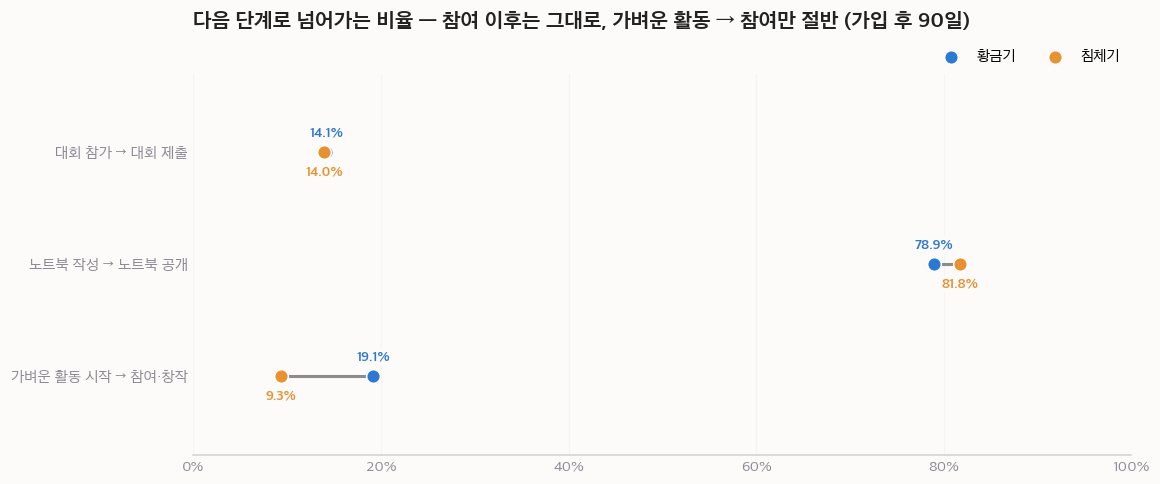

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(tr))[::-1]
for yi, (name, r) in zip(y, tr.iterrows()):
    ax.plot([r["황금기"], r["침체기"]], [yi, yi], color=vs.GRAY, lw=2, zorder=1)
    ax.scatter(r["황금기"], yi, color=vs.BLUE, s=80, zorder=3, edgecolor="white", label="황금기" if yi == y[0] else None)
    ax.scatter(r["침체기"], yi, color=vs.ORANGE, s=80, zorder=3, edgecolor="white", label="침체기" if yi == y[0] else None)
    for v, c, dy in [(r["황금기"], vs.BLUE, 10), (r["침체기"], vs.ORANGE, -16)]:
        ax.annotate(f"{v:.1%}", (v, yi), xytext=(0, dy), textcoords="offset points", ha="center", color=c, fontweight="bold", fontsize=9, bbox=vs.LABEL_BOX)
ax.set_yticks(y); ax.set_yticklabels(tr.index); ax.set_ylim(-0.7, len(tr) - 0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.3)
ax.set_title("다음 단계로 넘어가는 비율 — 참여 이후는 그대로, 가벼운 활동 → 참여만 절반 (가입 후 90일)", loc="left", fontweight="bold")
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/04_transitions.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## §5 견고성: 같은 날 순서 규칙을 뒤집으면

같은 날 가벼운 활동과 다른 활동이 함께 있으면 지금 규칙은 가벼운 활동을 앞에 둔다. 이 규칙이 "가벼운 활동 시작" 비중을 부풀릴 수 있으므로 **가벼운 활동을 맨 뒤로** 보내 다시 계산한다.

In [7]:
log_rev = build(raw, ORDER[1:] + ["가벼운 활동"])
first_rev = log_rev.groupby("UserId").agg(period=("period", "first"), first=("activity", "first"))
ft_rev = pd.crosstab(first_rev["first"], first_rev.period, normalize="columns").rename(columns=KO).loc[["가벼운 활동", "대회 참가"]]
print(ft_rev.applymap(lambda v: f"{v:.1%}"))
transitions(log_rev).style.format(TF)

period    황금기    침체기
first               
가벼운 활동  27.5%  44.1%
대회 참가   63.6%  42.3%


,황금기,침체기,비율 (침체/황금),95% CI,황금기 n,침체기 n
대회 참가 → 대회 제출,14.1%,13.9%,0.99,"[0.97, 1.00]","230,293","164,340"
노트북 작성 → 노트북 공개,79.0%,81.5%,1.03,"[1.02, 1.04]","22,691","39,690"
가벼운 활동 시작 → 참여·창작,11.0%,4.6%,0.41,"[0.40, 0.43]","94,656","163,130"


→ **결론 유지.** 가벼운 활동을 맨 뒤로 보내도 첫 활동이 가벼운 활동인 비중은 27.5% → 44.1%로 늘고, 그중 참여·창작으로 넘어가는 비율은 11.0% → 4.6%(비율 0.41)로 오히려 더 크게 줄어든다. 수준은 규칙에 따라 달라지지만 방향과 크기는 같다.

## 결론

1. **입구가 바뀌었다.** 황금기 가입자는 대회 참가로 들어왔고, 침체기 가입자는 가벼운 활동으로 들어온다.
2. **새 입구는 이어지지 않는다.** 가벼운 활동으로 시작한 유저가 참여·창작으로 넘어가는 비율이 절반(19.1% → 9.3%)이 됐다. 반면 대회 참가 → 제출, 노트북 작성 → 공개는 그대로다.
3. **`03` 결론을 보완한다.** `03`은 참여(팀 합류·노트북)로 시작한 유저만 봐서 "참여 이후 병목 없음"이었다. 그 앞 단계인 **가벼운 활동 → 참여** 연결은 크게 약해졌다. 다만 두 시기의 가벼운 활동 시작자는 다른 집단일 수 있어 시스템 병목으로 단정하지 않고 "가장 약해진 연결 고리"로 둔다.

**액션 (가설 수준)**: 투표·팔로우만 하는 신규 유저를 첫 참여(입문 대회, 노트북 포크 등)로 잇는 장치를 우선 검토한다. 효과는 A/B 테스트로 확인해야 한다.

**한계**: 날짜 단위라 같은 날 순서를 모른다(§5에서 확인). 반복 활동을 지웠으므로 빈도·재방문은 보지 않는다. 조회·다운로드는 기록이 없다.